### Correlation between climate and *An. gambiae* abundance in Greater Accra Ghana
 
This notebook uses the Common Data Model (CDM) you built to explore the relationship between 
weekly temperature/rainfall (ERA5‑Land) and the abundance of *An. gambiae s.l.* in Greater Accra, Ghana.
 
**Steps:**
1. Connect to the database and load required tables.
2. Filter data for Mombasa and the target species.
3. Aggregate vector observations to monthly abundance (because sampling is monthly).
4. Aggregate daily environmental data to monthly means.
5. Merge and visualise time series.
6. Compute correlation and lagged correlations.
7. Create a map of sampling sites with abundance.


#### 1. Setup and imports

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
import geopandas as gpd
from shapely import wkt
import contextily as ctx
import warnings
warnings.filterwarnings('ignore')

# Add project root to path (adjust if notebook is elsewhere)
project_root = Path.cwd().parent  # assumes notebook is in notebooks/
sys.path.append(str(project_root))

from database.session import engine
from database.models import Location, VectorObservation, EnvironmentalFactor


In [2]:
from dotenv import load_dotenv
import os
load_dotenv()  # you may need to specify the path if notebook is in a subfolder
print("SQL_LITE_DB_NAME:", os.getenv("SQL_LITE_DB_NAME"))
print("Current working directory:", os.getcwd())

SQL_LITE_DB_NAME: vbd_cdm.db
Current working directory: /home/void/Documents/codes/vbd-cdm/notebooks


In [3]:
from database.session import engine
from sqlalchemy import inspect
inspector = inspect(engine)
print(inspector.get_table_names())

['dim_time', 'environmental_factor', 'health_facility', 'host_case', 'intervention', 'location', 'resistance_test', 'socioeconomic', 'vector_observation']


In [4]:
# testing rainfall data values

# import xarray as xr
# ds = xr.open_dataset("/mnt/monadworld/projects/phd/article_manuscripts/a_cdm_for_vector_of_vbds/data/datasets/clipped/batch_results/2024_data/2024_data_Greater_Accra.nc")
# print(ds)
# print(ds['tp'].values[:5])  # first 5 time steps

In [5]:
# verify data exists

df_env = pd.read_sql("SELECT * FROM environmental_factor WHERE location_code = 'greater_accra'", engine)
print(f"Environmental records: {len(df_env)} days")

Environmental records: 732 days


#### 2. Load data from database

In [6]:
# Load all vector observations (limit to An. gambiae) along with their point geometries
query_vec = """
SELECT 
    v.date_id,
    v.location_code,
    v.vector_species,
    v.count,
    l.centroid_lat AS lat,
    l.centroid_lon AS lon,
    l.geometry_wkt AS geom_wkt
FROM vector_observation v
JOIN location l ON v.location_code = l.location_code
WHERE v.vector_species LIKE '%gambiae%'
"""
df_vec = pd.read_sql(query_vec, engine)
print(f"Total vector observations (all sites): {len(df_vec)}")

# Convert to GeoDataFrame (points)
gdf_points = gpd.GeoDataFrame(
    df_vec,
    geometry=gpd.points_from_xy(df_vec['lon'], df_vec['lat']),
    crs='EPSG:4326'
)

# Load the Greater Accra polygon from the location table
query_region = "SELECT geometry_wkt FROM location WHERE name = 'Greater Accra' AND admin_level = 'region'"
accra_wkt = pd.read_sql(query_region, engine).iloc[0, 0]
accra_polygon = wkt.loads(accra_wkt)
gdf_county = gpd.GeoDataFrame({'geometry': [accra_polygon]}, crs='EPSG:4326')

# Spatial filter: keep points within Greater Accra
gdf_accra = gdf_points[gdf_points.within(gdf_county.unary_union)]
print(f"Vector observations within Greater Accra: {len(gdf_accra)}")

# Convert back to DataFrame for time series
df_vec_accra = pd.DataFrame(gdf_accra.drop(columns='geometry'))
df_vec_accra['date'] = pd.to_datetime(df_vec_accra['date_id'])

# Load environmental data for Greater Accra
query_env = """
SELECT 
    date_id,
    temperature_mean,
    rainfall_total
FROM environmental_factor
WHERE location_code = 'greater_accra'
ORDER BY date_id
"""
df_env = pd.read_sql(query_env, engine)
df_env['date'] = pd.to_datetime(df_env['date_id'])
print(f"Environmental records: {len(df_env)} days")

Total vector observations (all sites): 12624
Vector observations within Greater Accra: 12312
Environmental records: 732 days


#### 3. Aggregate to monthly resolution

Vector observations are recorded monthly (first day of month). We'll average environmental data to monthly means.

In [7]:
# Aggregate vector observations by month (sum counts across all sites within Greater Accra)
df_vec_monthly = gdf_accra.groupby('date_id', as_index=False)['count'].sum()
df_vec_monthly['date'] = pd.to_datetime(df_vec_monthly['date_id'])
print(f"Monthly vector observations: {len(df_vec_monthly)} months")
print("Vector date range:", df_vec_monthly['date_id'].min(), "to", df_vec_monthly['date_id'].max())

# Aggregate environmental data to monthly means (use 'ME' for month end)
numeric_cols = ['temperature_mean', 'rainfall_total']
df_env_monthly = df_env.set_index('date')[numeric_cols].resample('ME').mean().reset_index()
df_env_monthly['date_id'] = df_env_monthly['date'].dt.strftime('%Y-%m-01')
print(f"Monthly environmental records: {len(df_env_monthly)} months")
print("Environmental date range:", df_env_monthly['date_id'].min(), "to", df_env_monthly['date_id'].max())

# Check for overlap
common_dates = set(df_vec_monthly['date_id']).intersection(set(df_env_monthly['date_id']))
print(f"Common months between vector and environmental data: {len(common_dates)}")

if len(common_dates) == 0:
    print("No overlapping months. Possible reasons:")
    print("- Vector observations may be from different years")
    print("- There might be a date format mismatch. Check sample dates:")
    print("  Vector sample date_id:", df_vec_monthly['date_id'].iloc[0] if len(df_vec_monthly) > 0 else "None")
    print("  Environmental sample date_id:", df_env_monthly['date_id'].iloc[0] if len(df_env_monthly) > 0 else "None")
    # Left merge to see which vector months are missing
    df_left = pd.merge(df_vec_monthly[['date_id', 'count']], 
                       df_env_monthly[['date_id', 'temperature_mean', 'rainfall_total']],
                       on='date_id', how='left')
    print("Vector months with missing environmental data (NaN):")
    print(df_left[df_left['temperature_mean'].isna()])
else:
    # Perform inner merge
    df_merged = pd.merge(
        df_vec_monthly[['date_id', 'count']],
        df_env_monthly[['date_id', 'temperature_mean', 'rainfall_total']],
        on='date_id',
        how='inner'
    )
    df_merged['date'] = pd.to_datetime(df_merged['date_id'])
    df_merged = df_merged.sort_values('date')
    print(f"Merged data: {len(df_merged)} months")

Monthly vector observations: 3 months
Vector date range: 2023-01-01 to 2025-01-01
Monthly environmental records: 25 months
Environmental date range: 2023-12-01 to 2025-12-01
Common months between vector and environmental data: 2
Merged data: 2 months


#### 4. Visualise time series

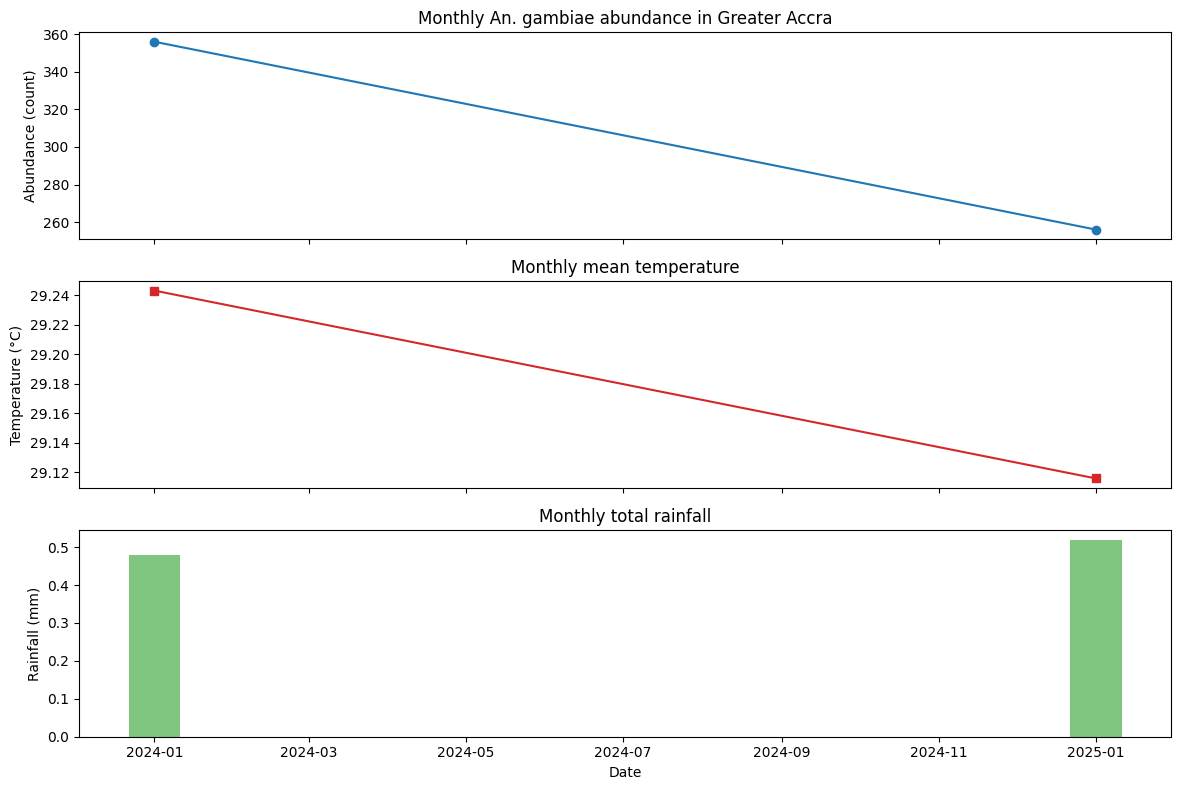

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# Abundance
axes[0].plot(df_merged['date'], df_merged['count'], marker='o', linestyle='-', color='tab:blue')
axes[0].set_ylabel('Abundance (count)')
axes[0].set_title('Monthly An. gambiae abundance in Greater Accra')

# Temperature
axes[1].plot(df_merged['date'], df_merged['temperature_mean'], marker='s', linestyle='-', color='tab:red')
axes[1].set_ylabel('Temperature (°C)')
axes[1].set_title('Monthly mean temperature')

# Rainfall
axes[2].bar(df_merged['date'], df_merged['rainfall_total'], width=20, color='tab:green', alpha=0.6)
axes[2].set_ylabel('Rainfall (mm)')
axes[2].set_title('Monthly total rainfall')

plt.xlabel('Date')
plt.tight_layout()
plt.show()

#### 5. Correlation analysis

Correlation with temperature: 1.000
Correlation with rainfall: -1.000


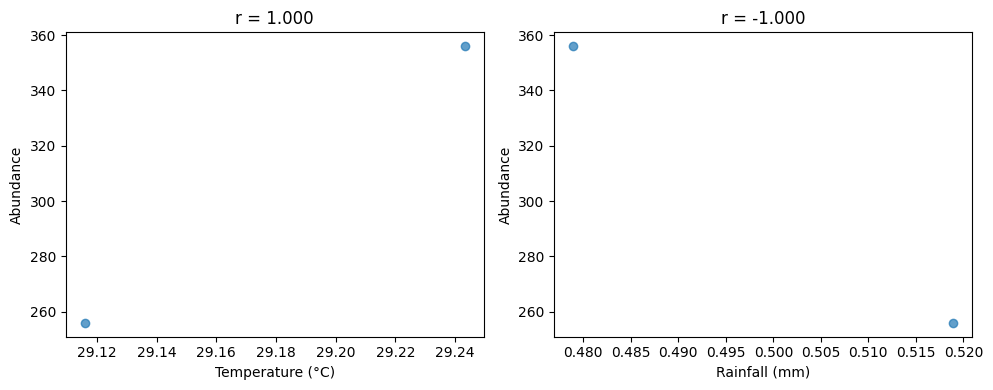

In [9]:
# Simple Pearson correlation
corr_temp = df_merged['temperature_mean'].corr(df_merged['count'])
corr_rain = df_merged['rainfall_total'].corr(df_merged['count'])

print(f"Correlation with temperature: {corr_temp:.3f}")
print(f"Correlation with rainfall: {corr_rain:.3f}")

# Scatter plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(df_merged['temperature_mean'], df_merged['count'], alpha=0.7)
axes[0].set_xlabel('Temperature (°C)')
axes[0].set_ylabel('Abundance')
axes[0].set_title(f'r = {corr_temp:.3f}')

axes[1].scatter(df_merged['rainfall_total'], df_merged['count'], alpha=0.7)
axes[1].set_xlabel('Rainfall (mm)')
axes[1].set_ylabel('Abundance')
axes[1].set_title(f'r = {corr_rain:.3f}')

plt.tight_layout()
plt.show()

##### Lagged correlations

Vector abundance may respond to climate with a delay (e.g., rainfall from previous month). We'll compute correlations with lags of 1–3 months.

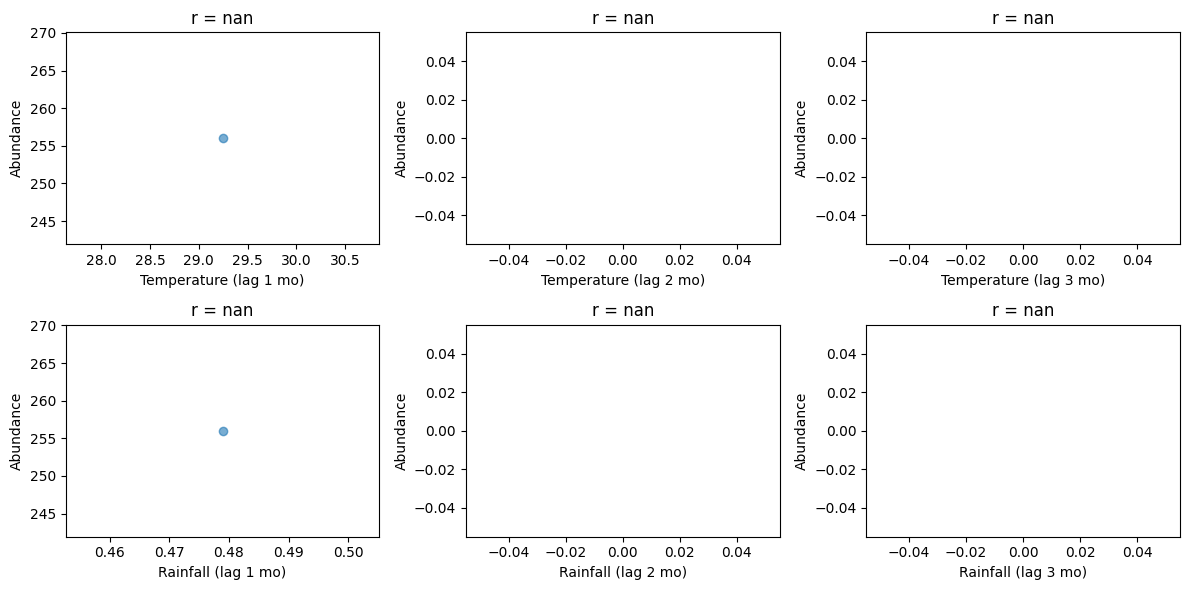

In [10]:
from pandas.plotting import lag_plot

fig, axes = plt.subplots(2, 3, figsize=(12, 6))

lags = [1, 2, 3]
for i, lag in enumerate(lags):
    # Lag temperature
    df_temp_lag = df_merged[['temperature_mean', 'count']].copy()
    df_temp_lag['temp_lag'] = df_temp_lag['temperature_mean'].shift(lag)
    # Drop rows where either the lag or count is NaN
    df_temp_lag_clean = df_temp_lag.dropna(subset=['temp_lag', 'count'])
    corr_lag = df_temp_lag_clean[['temp_lag', 'count']].corr().iloc[0,1]
    axes[0,i].scatter(df_temp_lag_clean['temp_lag'], df_temp_lag_clean['count'], alpha=0.6)
    axes[0,i].set_xlabel(f'Temperature (lag {lag} mo)')
    axes[0,i].set_ylabel('Abundance')
    axes[0,i].set_title(f'r = {corr_lag:.3f}')
    
    # Lag rainfall
    df_rain_lag = df_merged[['rainfall_total', 'count']].copy()
    df_rain_lag['rain_lag'] = df_rain_lag['rainfall_total'].shift(lag)
    df_rain_lag_clean = df_rain_lag.dropna(subset=['rain_lag', 'count'])
    corr_lag = df_rain_lag_clean[['rain_lag', 'count']].corr().iloc[0,1]
    axes[1,i].scatter(df_rain_lag_clean['rain_lag'], df_rain_lag_clean['count'], alpha=0.6)
    axes[1,i].set_xlabel(f'Rainfall (lag {lag} mo)')
    axes[1,i].set_ylabel('Abundance')
    axes[1,i].set_title(f'r = {corr_lag:.3f}')

axes[0,0].set_ylabel('Abundance')
axes[1,0].set_ylabel('Abundance')
plt.tight_layout()
plt.show()

#### 6. Map of sampling sites in Siaya with abundance

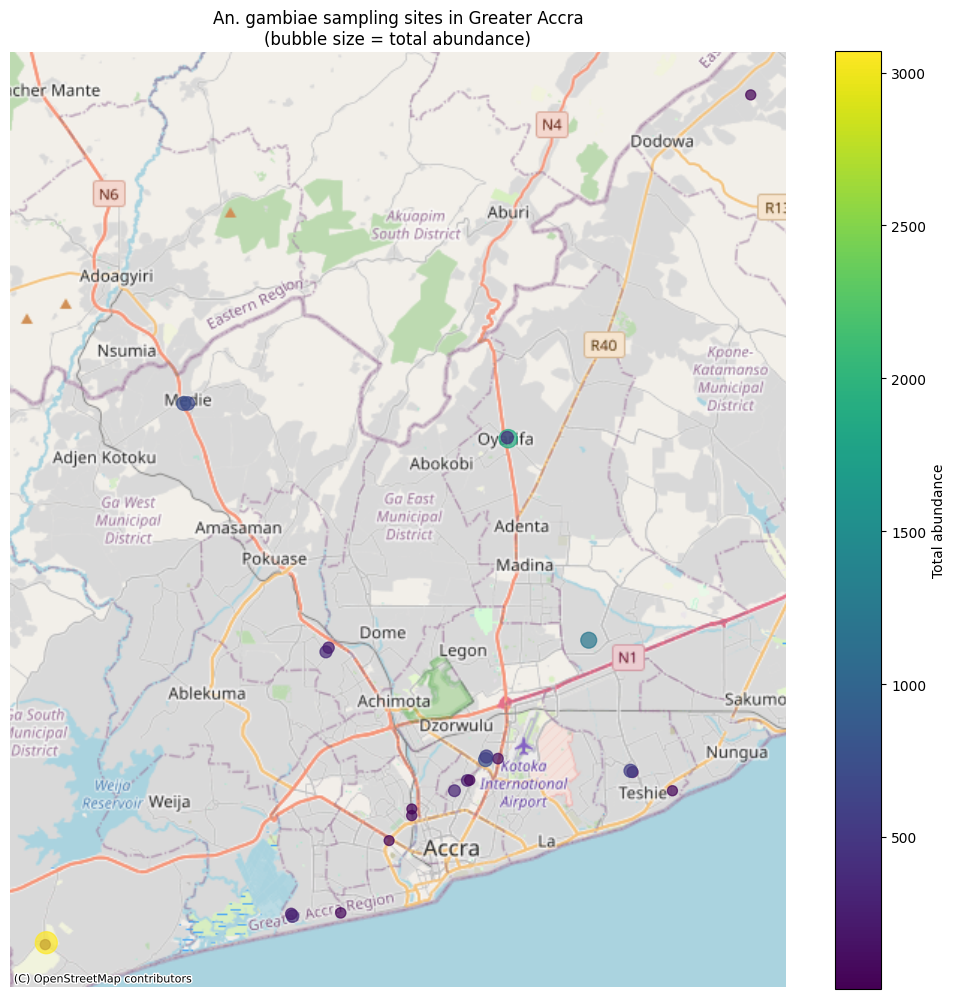

In [11]:
# Aggregate vector observations by site within Greater Accra
df_sites_accra = gdf_accra.groupby(['location_code', 'lat', 'lon'], as_index=False)['count'].sum()
gdf_sites = gpd.GeoDataFrame(
    df_sites_accra,
    geometry=gpd.points_from_xy(df_sites_accra['lon'], df_sites_accra['lat']),
    crs='EPSG:4326'
)

# Convert to Web Mercator for basemap
gdf_sites_3857 = gdf_sites.to_crs(epsg=3857)

# Plot
fig, ax = plt.subplots(figsize=(10, 10))
gdf_sites_3857.plot(
    ax=ax,
    markersize=gdf_sites_3857['count'] / gdf_sites_3857['count'].max() * 200 + 50,
    column='count',
    cmap='viridis',
    alpha=0.7,
    legend=True,
    legend_kwds={'label': 'Total abundance'}
)

# Add basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik)

ax.set_title('An. gambiae sampling sites in Greater Accra\n(bubble size = total abundance)')
ax.set_axis_off()
plt.tight_layout()
plt.show()

#### 7. Interpretation

Based on the plots and correlations, we can see:
- (Describe observed relationships, e.g., positive correlation with rainfall lagged by 1 month)
- The map shows where most sampling occurred and which sites had high abundance.
 
This analysis demonstrates the power of your CDM to integrate environmental and vector data for epidemiological insights.


#### 8. Next steps

- Incorporate additional variables (e.g., NDVI, land use) from GEE.
- Apply time series models (e.g., ARIMAX) to forecast abundance.
- Extend the analysis to other counties and species.